# # 03 · Encoder–decoder Transformer (original Transformer / T5 / BART / Whisper)
#
# Two stacks:
# * an **encoder** reads the whole input with bidirectional attention → a "memory" of vectors;
# * a **decoder** generates the output left-to-right with causal self-attention **plus cross-attention** to that memory.
#
# Cross-attention is what lets the output look back at the input — we use the *reverse a word* task so you can literally
# see an anti-diagonal alignment emerge.

In [1]:
import math
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np
from llmarch import *
set_seed(0); device = get_device()
d = load_seq2seq_data(); itos, PAD, BOS, EOS, V = d["itos"], d["pad"], d["bos"], d["eos"], d["vocab_size"]
src_tr, tgt_tr = [t.to(device) for t in d["train"]]; src_va, tgt_va = [t.to(device) for t in d["val"]]

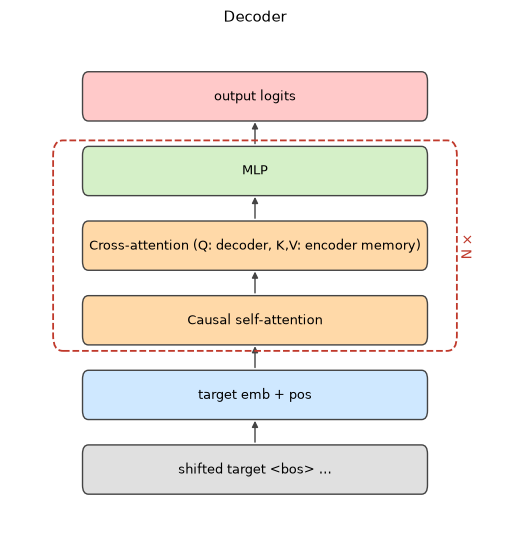

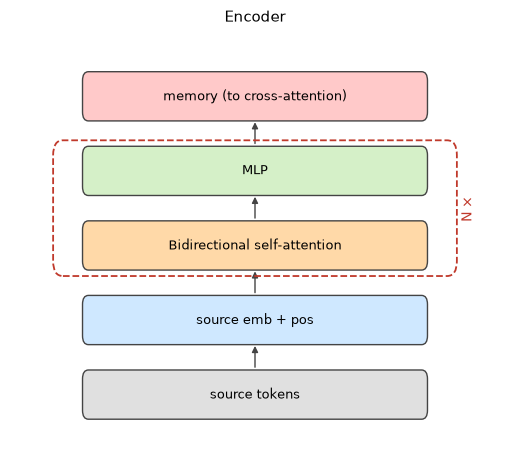

In [2]:
block_diagram([("output logits", "out"), ("MLP", "ffn*"), ("Cross-attention (Q: decoder, K,V: encoder memory)", "attn*"), ("Causal self-attention", "attn*"),
               ("target emb + pos", "embed"), ("shifted target <bos> …", "other")][::-1], title="Decoder", repeat="N ×", figsize=(5.2, None))
block_diagram([("memory (to cross-attention)", "out"), ("MLP", "ffn*"), ("Bidirectional self-attention", "attn*"), ("source emb + pos", "embed"), ("source tokens", "other")][::-1],
              title="Encoder", repeat="N ×", figsize=(5.2, None))

# ## Implementation (built on `nn.MultiheadAttention` so we can read the cross-attention weights)

In [3]:
class EncLayer(nn.Module):
    def __init__(s, d, h):
        super().__init__(); s.n1, s.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.sa = nn.MultiheadAttention(d, h, batch_first=True); s.ff = nn.Sequential(nn.Linear(d, 4*d), nn.GELU(), nn.Linear(4*d, d))
    def forward(s, x, pad):
        h = s.n1(x); x = x + s.sa(h, h, h, key_padding_mask=pad, need_weights=False)[0]
        return x + s.ff(s.n2(x))

class DecLayer(nn.Module):
    def __init__(s, d, h):
        super().__init__(); s.n1, s.n2, s.n3 = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d)
        s.sa = nn.MultiheadAttention(d, h, batch_first=True); s.ca = nn.MultiheadAttention(d, h, batch_first=True)
        s.ff = nn.Sequential(nn.Linear(d, 4*d), nn.GELU(), nn.Linear(4*d, d)); s.cross_w = None
    def forward(s, y, mem, causal, mem_pad):
        h = s.n1(y); y = y + s.sa(h, h, h, attn_mask=causal, need_weights=False)[0]
        a, w = s.ca(s.n2(y), mem, mem, key_padding_mask=mem_pad, need_weights=True, average_attn_weights=False)
        s.cross_w = w.detach()                                    # (B, heads, T_tgt, T_src)
        y = y + a
        return y + s.ff(s.n3(y))

class Seq2Seq(nn.Module):
    def __init__(s, V, d=64, h=4, n=2, L=16):
        super().__init__(); s.emb, s.pos = nn.Embedding(V, d), nn.Embedding(L, d)
        s.enc = nn.ModuleList([EncLayer(d, h) for _ in range(n)]); s.dec = nn.ModuleList([DecLayer(d, h) for _ in range(n)])
        s.ne, s.nd = nn.LayerNorm(d), nn.LayerNorm(d); s.head = nn.Linear(d, V)
    def encode(s, src):
        pad = src == PAD; x = s.emb(src) + s.pos(torch.arange(src.size(1), device=src.device))
        for l in s.enc: x = l(x, pad)
        return s.ne(x), pad
    def decode(s, tgt_in, mem, pad):
        T = tgt_in.size(1); causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=tgt_in.device), 1)
        y = s.emb(tgt_in) + s.pos(torch.arange(T, device=tgt_in.device))
        for l in s.dec: y = l(y, mem, causal, pad)
        return s.head(s.nd(y))
    def forward(s, src, tgt_in):
        mem, pad = s.encode(src); return s.decode(tgt_in, mem, pad)

model = Seq2Seq(V).to(device); print(f"{count_params(model)/1e6:.3f} M params")
_ = show_summary(model, input_data=(src_tr[:1], tgt_tr[:1, :-1]), depth=1)

0.238 M params
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Seq2Seq                                  [1, 10]                   [1, 9, 29]                --
├─Embedding: 1-1                         [1, 10]                   [1, 10, 64]               1,856
├─Embedding: 1-2                         [10]                      [10, 64]                  1,024
├─ModuleList: 1-3                        --                        --                        99,968
├─LayerNorm: 1-4                         [1, 10, 64]               [1, 10, 64]               128
├─Embedding: 1-5                         [1, 9]                    [1, 9, 64]                (recursive)
├─Embedding: 1-6                         [9]                       [9, 64]                   (recursive)
├─ModuleList: 1-7                        --                        --                        133,504
├─LayerNorm: 1-8                         [1, 9, 64]                [1, 9, 64]     

# ## Train with teacher forcing

300 0.0384


600 0.0008


900 0.0005


1200 0.0003


1500 0.0002


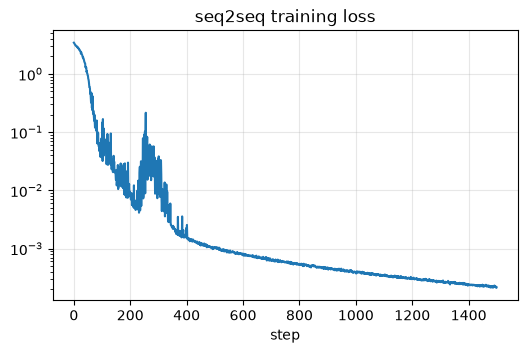

In [4]:
opt = torch.optim.AdamW(model.parameters(), lr=2e-3); STEPS = 1500; losses = []
for step in range(STEPS):
    ix = torch.randint(len(src_tr), (64,)); s, t = src_tr[ix], tgt_tr[ix]
    lg = model(s, t[:, :-1]); loss = F.cross_entropy(lg.reshape(-1, V), t[:, 1:].reshape(-1), ignore_index=PAD)
    opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    if (step + 1) % 300 == 0: print(step + 1, f"{np.mean(losses[-50:]):.4f}")
plt.figure(figsize=(6, 3.5)); plt.semilogy(losses); plt.title("seq2seq training loss"); plt.xlabel("step"); plt.grid(alpha=.3); plt.show()

# ## Greedy decoding & accuracy
# The encoder runs **once**; the decoder runs token by token, re-using the memory.

In [5]:
@torch.no_grad()
def translate(src, maxlen=11):
    model.eval(); mem, pad = model.encode(src); out = torch.full((len(src), 1), BOS, device=src.device)
    for _ in range(maxlen - 1):
        nxt = model.decode(out, mem, pad)[:, -1].argmax(-1, keepdim=True); out = torch.cat([out, nxt], 1)
    return out
def dec(row):                                   # drop <bos>/<pad>, stop at the first <eos>
    out = []
    for t in row:
        if t == EOS: break
        if t > 2: out.append(itos[t])
    return "".join(out)
pred = translate(src_va); ok = [dec(p.tolist()) == dec(t.tolist()) for p, t in zip(pred, tgt_va)]
print(f"exact-match accuracy on held-out pairs: {np.mean(ok):.1%}")
for i in range(6): print(dec(src_va[i].tolist()), "->", dec(pred[i].tolist()), "| target", dec(tgt_va[i].tolist()))
fake = {"step": list(range(1, STEPS + 1)), "train": losses, "val_step": [STEPS], "val": [float(np.mean(losses[-50:]))]}
save_result("03 Encoder-decoder (seq2seq reverse task)", model, fake, extra={"exact_match": float(np.mean(ok)), "note": "different task"})

exact-match accuracy on held-out pairs: 100.0%
plbfany -> ynafblp | target ynafblp
gvzxa -> axzvg | target axzvg
nat -> tan | target tan
hizbtpn -> nptbzih | target nptbzih
dbqoitvb -> bvtioqbd | target bvtioqbd
phkhlgmm -> mmglhkhp | target mmglhkhp


{'params': 238493,
 'val_loss': 0.00022415997023927047,
 'train_loss': 0.00022049574836273677,
 'exact_match': 1.0,
 'note': 'different task'}

# ## Cross-attention: the model learned to *reverse*
# Rows = output step, columns = input position. A bright **anti-diagonal** means "output 1 reads input last, output 2 reads
# input second-to-last…" — learned entirely from data.

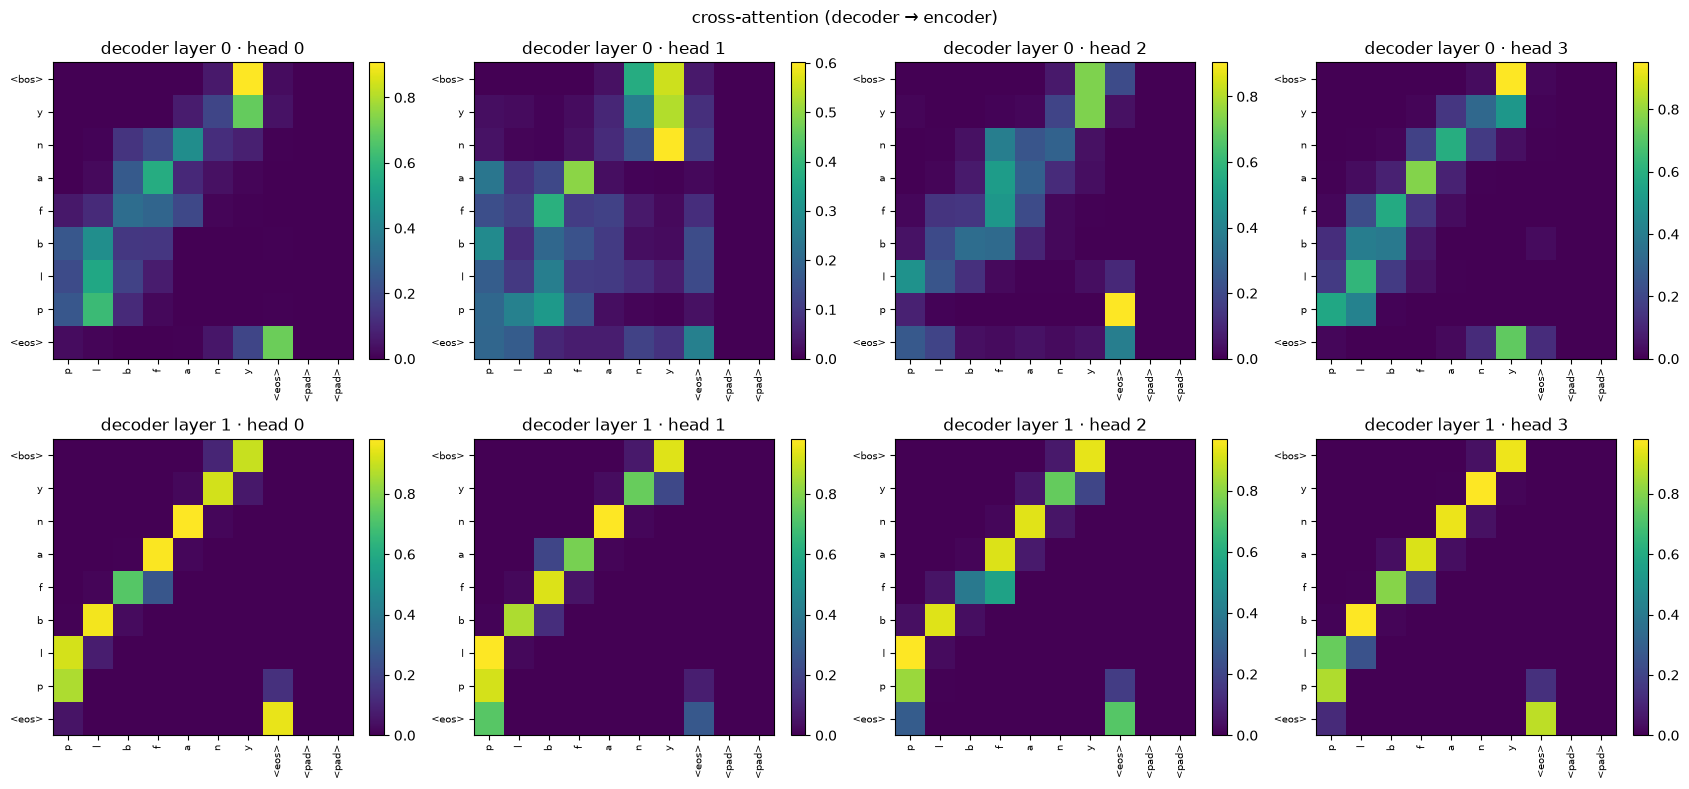

In [6]:
i = next(j for j in range(len(src_va)) if (src_va[j] > 2).sum() == 7)
s1, t1 = src_va[i:i+1], tgt_va[i:i+1]; model.eval(); model(s1, t1[:, :-1])
sl = ["".join(itos[t]) for t in s1[0].tolist()]; tl = [itos[t] for t in t1[0, :-1].tolist()]
fig, axs = plt.subplots(2, 4, figsize=(17, 8))
for l in range(2):
    for h in range(4): plot_heatmap(model.dec[l].cross_w[0, h].cpu(), sl, tl, f"decoder layer {l} · head {h}", ax=axs[l, h])
plt.suptitle("cross-attention (decoder → encoder)"); plt.tight_layout(); plt.show()